# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

try:                                   # only available (and needed) in Google Colab
    from google.colab import files
except ImportError:
    pass

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
import os

# Works in Colab (/content/...) and locally (same folder as the notebook)
for path in ["/content/Lab_11_QnA_Dataset_Download.csv", "/content/Lab_11_QnA_Dataset.csv",
             "Lab_11_QnA_Dataset_Download.csv", "Lab_11_QnA_Dataset.csv"]:
    if os.path.exists(path):
        df = pd.read_csv(path)
        break
else:
    raise FileNotFoundError("Upload Lab_11_QnA_Dataset.csv next to the notebook")

print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

I0000 00:00:1793549177.777965     168 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793549177.826294     168 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793549180.440980     168 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)  # batch_first=True: each question is its own sequence
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #clear the gradients from the previous epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

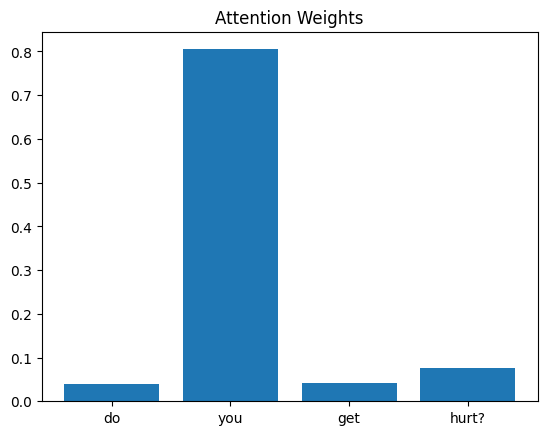

In [6]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Training accuracy: 98.2%



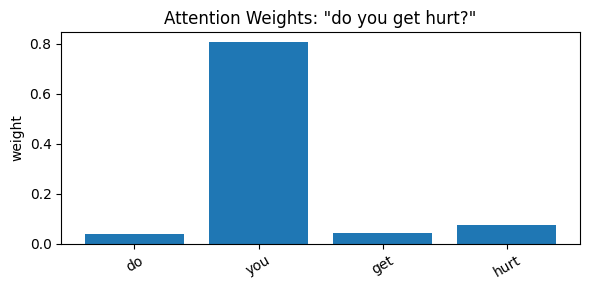

Question: "do you get hurt?"
  Highest-attention word: "you" (weight 0.805)
  Correct answer_id: 0 | model predicts: 0



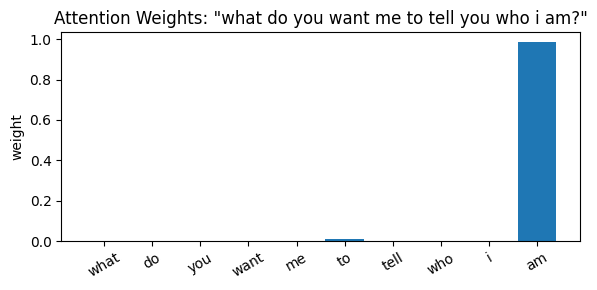

Question: "what do you want me to tell you who i am?"
  Highest-attention word: "am" (weight 0.985)
  Correct answer_id: 2 | model predicts: 2



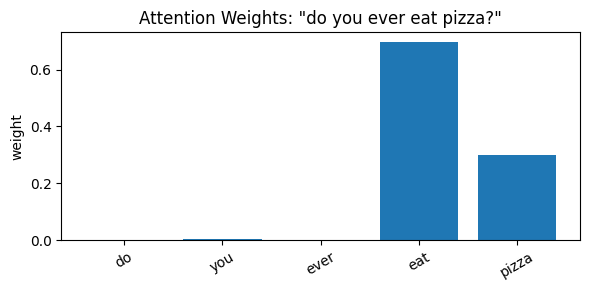

Question: "do you ever eat pizza?"
  Highest-attention word: "eat" (weight 0.696)
  Correct answer_id: 7 | model predicts: 7



In [7]:
# How well did the model learn? (accuracy on the training questions)
with torch.no_grad():
    train_accuracy = (model(X)[0].argmax(1) == y).float().mean().item()
print(f"Training accuracy: {train_accuracy:.1%}\n")

def show_attention(idx):
    """Plot the attention weights of question number `idx` and return its words, weights and predicted answer."""
    question = df["question"][idx]
    # use the tokenizer's own words so the bars line up exactly with the model's input
    words = [tokenizer.index_word[i] for i in tokenizer.texts_to_sequences([question])[0]]

    with torch.no_grad():
        prediction, weights = model(X[idx:idx + 1])

    w = weights[0, :len(words)].tolist()
    plt.figure(figsize=(6, 3))
    plt.bar(words, w)
    plt.title(f'Attention Weights: "{question}"')
    plt.ylabel("weight")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

    best = words[w.index(max(w))]
    predicted = prediction.argmax(1).item()
    return words, w, best, predicted

# Three questions from three different answer groups
for idx in [0, 30, 100]:
    words, w, best, predicted = show_attention(idx)
    print(f'Question: "{df["question"][idx]}"')
    print(f'  Highest-attention word: "{best}" (weight {max(w):.3f})')
    print(f'  Correct answer_id: {df["answer_id"][idx]} | model predicts: {predicted}\n')

**Answer (Task 1):**

The results are **mixed**:

- *"do you ever eat pizza?"*: the weight is on **"eat"** (0.70) and **"pizza"** (0.30), the two content words that give the question its meaning. This is what we hope to see.
- *"what do you want me to tell you who i am?"*: almost all the weight (0.99) is on the last word, **"am"**. It is part of the key phrase "who i am", but a single word does not capture the whole question.
- *"do you get hurt?"*: the highest weight is on **"you"** (0.81), while the more meaningful word **"hurt"** gets only about 0.07. Here the model is not focusing on the word a person would call most important.

So the highest-attention word is sometimes an important word and sometimes not. The model is only trained to pick the correct answer out of 12, so it learns to attend to whichever words help it do that on this small dataset, which are not always the words a human would choose. (Note that the model was trained and tested on the same 168 questions, with 98% training accuracy, so these weights say little about new questions.)

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

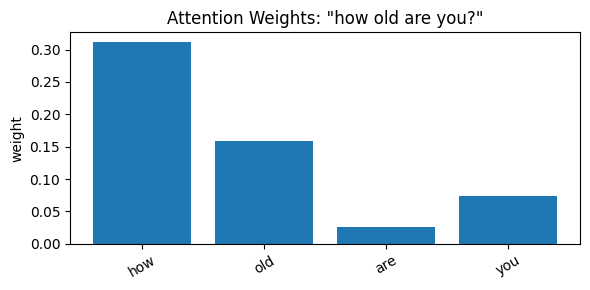

Question: "how old are you?"
  Words and weights: how=0.311, old=0.158, are=0.026, you=0.074
  Highest-attention word: "how"
  Correct answer_id: 1 | model predicts: 1



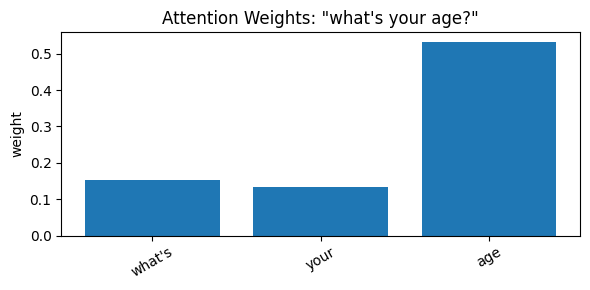

Question: "what's your age?"
  Words and weights: what's=0.152, your=0.133, age=0.532
  Highest-attention word: "age"
  Correct answer_id: 1 | model predicts: 1



In [8]:
# Two questions with the same meaning (both ask for the age) but different wording
idx_a = df.index[df["question"] == "how old are you?"][0]
idx_b = df.index[df["question"] == "what's your age?"][0]

for idx in [idx_a, idx_b]:
    words, w, best, predicted = show_attention(idx)
    print(f'Question: "{df["question"][idx]}"')
    print(f'  Words and weights: ' + ", ".join(f"{wd}={wt:.3f}" for wd, wt in zip(words, w)))
    print(f'  Highest-attention word: "{best}"')
    print(f'  Correct answer_id: {df["answer_id"][idx]} | model predicts: {predicted}\n')

**Answer (Task 2):**

The two questions mean the same thing and the model gives both the correct answer (answer 1, about age), but it looks at **different words** in each: in *"how old are you?"* the highest weight is on **"how"** (0.31), followed by **"old"** (0.16), while in *"what's your age?"* it is on **"age"** (0.53). The age-related words (**old**, **age**) get a large share of attention in both, but the exact word with the top weight is different.

This suggests that attention does not work like a fixed list of "important words". Each weight is learned from the words and their context in that particular question, and the model can reach the same answer through different words. The weights show which words the model used as evidence, which is useful for inspecting it, but they should not be read as proof that the model "understands" the meaning. (Note: the weights shown for the real words do not add up to 1 because the model also gives some weight to the zero-padding positions at the end of each padded question.)